# Multicolinealidad

> Romero Medina Emiliano

En esta prática guiada comprobaremos la existencia de multicolinealidad, como identificarla y como tratar de corregirla, todo esto a través de los datos contenidos en la base de datos "Fish.csv" que cargamos y observamos a continuación.

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from statsmodels.stats.outliers_influence import variance_inflation_factor
np.random.seed(123)

path = "/content/drive/MyDrive/Modelos Lineales/Tareas/Practica Guiada 1 -  Multicolinealidad con python/Fish.csv"
fish_df = pd.read_csv(path)
fish_df = pd.DataFrame(fish_df)
fish_df

,Species,Weight,Length1,Length2,Length3,Height,Price
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340
...,...,...,...,...,...,...,...
154,Smelt,12.2,11.5,12.2,13.4,2.0904,1.3936
155,Smelt,13.4,11.7,12.4,13.5,2.4300,1.2690
156,Smelt,12.2,12.1,13.0,13.8,2.2770,1.2558
157,Smelt,19.7,13.2,14.3,15.2,2.8728,2.0672


Dentro de los datos podemos identificar diferentes variables, en particular Species es una variable categórica, las restantes son variables numéricas. En particular las variables explican lo siguiente:

* Species: Especie del pez. Variable categórica con siete posibles categorías: Bream, Parkki, Perch, Pike, Roach, Smelt y Whitefish.
* Weight: Peso del pez, medido en gramos.
* Length1: primera medición de longitud del pez, en centímetros.
* Length2: segunda medición de longitud del pez, en centímetros.
* Length3: tercera medición de longitud del pez, en centímetros.
* Height: altura del pez, en centímetros.
* Width: ancho del pez, en centímetros.

Dado que Species es una categoría, veamos la matriz de correlaciones de las variables numéricas a través de un mapa de calor.

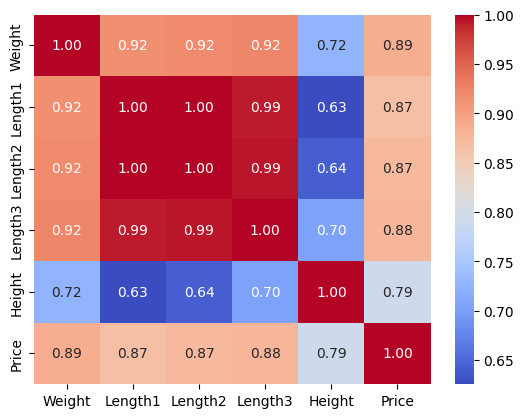

In [ ]:
matriz_corr = fish_df.drop(fish_df.columns[0], axis=1).corr()
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

Dónde podemos observar que varias de las variables independientes o explicativas tienen correlaciones elevadas; las más sospechosas las que involucran a las variables Length1, Length2 y Length3 teniendo correlaciones perfectas (1) y casi perfectas (0.99) además la variable Weight tiene una correlación de 0.92 con las tres variables antes mencionadas, lo que es evidencia para anlizar más a fondo la existenciad e multicolinealidad.

Ahora para considerar a la variable Species dentro de nuestro análisis de multicolinealidad hacemos una transformación mediante One-Hot Encoding, obteniendo una indicadora para cada especie.

In [ ]:
from sklearn.preprocessing import OneHotEncoder
categoricals = ['Species']
encoder = OneHotEncoder(handle_unknown = 'ignore', sparse_output = False).fit(fish_df[categoricals])
ohe_columns = list(encoder.get_feature_names_out(categoricals))
X_ohe = pd.DataFrame(encoder.transform(fish_df[categoricals]), columns = ohe_columns)
X_ohe

,Species_Bream,Species_Parkki,Species_Perch,Species_Pike,Species_Roach,Species_Smelt,Species_Whitefish
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...
154,0.0,0.0,0.0,0.0,0.0,1.0,0.0
155,0.0,0.0,0.0,0.0,0.0,1.0,0.0
156,0.0,0.0,0.0,0.0,0.0,1.0,0.0
157,0.0,0.0,0.0,0.0,0.0,1.0,0.0


Con esta codificación procedemos a construir el conjunto de datos de los predictores, con los cuales se quiere predecir o estudiar la variable objetivo Price.

In [ ]:
numerical = ['Weight', 'Length1', 'Length2', 'Length3', 'Height']
fish_df1 = pd.concat([fish_df, X_ohe], axis = 1)
fish_df1

,Species,Weight,Length1,Length2,Length3,Height,Price,Species_Bream,Species_Parkki,Species_Perch,Species_Pike,Species_Roach,Species_Smelt,Species_Whitefish
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
154,Smelt,12.2,11.5,12.2,13.4,2.0904,1.3936,0.0,0.0,0.0,0.0,0.0,1.0,0.0
155,Smelt,13.4,11.7,12.4,13.5,2.4300,1.2690,0.0,0.0,0.0,0.0,0.0,1.0,0.0
156,Smelt,12.2,12.1,13.0,13.8,2.2770,1.2558,0.0,0.0,0.0,0.0,0.0,1.0,0.0
157,Smelt,19.7,13.2,14.3,15.2,2.8728,2.0672,0.0,0.0,0.0,0.0,0.0,1.0,0.0


Con esta información ya con la variable categórica codificada, ajustemos un modelo inicial. La variable Price será la variable respuesta, y las variables predictoras serán las númericas y las que creamos anteriormente. Veamos si hay algo que haga evidente la colinealidad.

In [ ]:
import statsmodels.api as sm
predictors = numerical + ohe_columns
target = "Price"

X_reg = fish_df1[predictors]
Y_reg = fish_df1[target]

regression_model = sm.OLS(Y_reg,X_reg).fit()
print(regression_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.966
Model:                            OLS   Adj. R-squared:                  0.963
Method:                 Least Squares   F-statistic:                     376.4
Date:                Sun, 20 Sep 2026   Prob (F-statistic):          1.03e-101
Time:                        18:53:28   Log-Likelihood:                -39.991
No. Observations:                 159   AIC:                             104.0
Df Residuals:                     147   BIC:                             140.8
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Weight            -6.132e-06      0.00

El modelo presenta un $R^2$ de 0.966, lo que indica que aproximadamente el 96.6% de la variabilidad de Price es explicada por las variables incluidas. Asimismo, la prueba F global resulta estadísticamente significativa (F = 376.4, p < 0.001), por lo que, en conjunto, las variables explicativas aportan información significativa para explicar Price.

Al analizar los coeficientes individuales, Height presenta un efecto positivo y estadísticamente significativo sobre Price (p < 0.001). Entre las variables de Species, Bream (p < 0.001), Parkki (p < 0.001), Pike (p = 0.034) y Smelt (p = 0.049) son significativas. Por otro lado, Perch, Roach y Whitefish no presentan evidencia suficiente de que sus coeficientes sean diferentes de cero al 5%.

Para Weight, Length1, Length2 y Length3 tampoco se encontró significancia estadística al 5%. En particular, Weight presenta un coeficiente prácticamente igual a cero y un p = 0.983. Sin embargo, esto no implica necesariamente que no tenga relación con Price, ya que puede existir multicolinealidad entre las variables físicas del pez, debido a que Weight, Length1, Length2, Length3 y Height están relacionadas entre sí.

Además, el Condition Number de 1.67 × 10⁴ representa una señal de posible multicolinealidad y/o diferencias importantes en las escalas de las variables. Por ello, se recomienda complementar el diagnóstico mediante el cálculo de los VIF. Aunque esto aumenta las sospechas de multicolinealidad que ya observabamos en las correlaciones.

En el siguiente punto se calcularan los $R^2$ y VIF y en dado caso que superen un $R^2 = 0.7$ se eliminaran esas variables y procedemos a un nuevo cálculo, de manera iterativa hasta quedarnos con las variables no multicolineales.

In [ ]:
def eliminar_multicolinealidad(df, max_vif=5):
    # Creamos una copia para no modificar el DataFrame original
    df_work = df.copy()

    # Lista para registrar las variables eliminadas
    removed_vars = []

    # Contador de iteraciones
    iteration = 0

    print("=== ELIMINACIÓN PASO A PASO DE MULTICOLINEALIDAD ===")

    # Repetimos el procedimiento hasta que todos los VIF sean aceptables
    while True:
        iteration += 1
        print(f"\n--- PASO {iteration} ---")

        try:
            # Calculamos el VIF de cada predictor con las variables actuales
            vif_data = pd.DataFrame()
            vif_data["Variable"] = df_work.columns
            vif_data["VIF"] = [
                variance_inflation_factor(df_work.values, i)
                for i in range(len(df_work.columns))
            ]

            # Ordenamos las variables de mayor a menor VIF
            vif_data = vif_data.sort_values('VIF', ascending=False)

            # Mostramos el VIF actual de cada variable
            print("VIF actual:")
            for _, row in vif_data.iterrows():
                status = "🔴" if row['VIF'] > 10 else "🟡" if row['VIF'] > 5 else "✅"
                print(f"  {row['Variable']}: {row['VIF']:.2f} {status}")

            # Identificamos el VIF más alto
            max_vif_current = vif_data['VIF'].max()

            # Si todos los VIF cumplen el criterio, detenemos el proceso
            if max_vif_current <= max_vif:
                print(f"\n✅ ÉXITO: Todos los VIF <= {max_vif}")
                break

            # Seleccionamos la variable con el VIF más alto
            var_to_remove = vif_data.iloc[0]['Variable']
            vif_value = vif_data.iloc[0]['VIF']

            print(f"\n🗑️ ELIMINANDO: {var_to_remove} (VIF = {vif_value:.2f})")

            # Eliminamos la variable y registramos su nombre
            df_work = df_work.drop(columns=[var_to_remove])
            removed_vars.append(var_to_remove)

            print(f"Variables restantes: {list(df_work.columns)}")

        # Detenemos el procedimiento si ocurre un error
        except Exception as e:
            print(f"❌ Error en cálculo VIF: {e}")
            break

        # Evitamos continuar si solamente queda un predictor
        if len(df_work.columns) <= 1:
            print("⚠️ Solo queda 1 variable. Proceso detenido.")
            break

    # Mostramos el resultado del procedimiento
    preserved_vars = list(df_work.columns)
    print(f"\n=== RESULTADO FINAL ===")
    print(f"Variables eliminadas: {removed_vars}")
    print(f"Variables finales: {preserved_vars}")

    # Devolvemos los predictores conservados y los eliminados
    return df_work, removed_vars, preserved_vars

In [ ]:
max_R2 = 0.7
max_vif = 1/(1-max_R2)
print(f"Máximo VIF: {max_vif}")
X_nomlc, removidas, conservadas = eliminar_multicolinealidad(X_reg, max_vif)
col_conservadas = list(X_nomlc.columns)


Máximo VIF: 3.333333333333333
=== ELIMINACIÓN PASO A PASO DE MULTICOLINEALIDAD ===

--- PASO 1 ---
VIF actual:
  Species_Pike: 1000799917193443.50 🔴
  Species_Perch: 1000799917193443.50 🔴
  Species_Parkki: 1000799917193443.50 🔴
  Species_Bream: 1000799917193443.50 🔴
  Species_Smelt: 1000799917193443.50 🔴
  Species_Roach: 1000799917193443.50 🔴
  Species_Whitefish: 1000799917193443.50 🔴
  Length2: 4354.94 🔴
  Length1: 2428.54 🔴
  Length3: 2057.88 🔴
  Height: 37.12 🔴
  Weight: 15.65 🔴

🗑️ ELIMINANDO: Species_Pike (VIF = 1000799917193443.50)
Variables restantes: ['Weight', 'Length1', 'Length2', 'Length3', 'Height', 'Species_Bream', 'Species_Parkki', 'Species_Perch', 'Species_Roach', 'Species_Smelt', 'Species_Whitefish']

--- PASO 2 ---
VIF actual:
  Length2: 4354.94 🔴
  Length1: 2428.54 🔴
  Length3: 2057.88 🔴
  Species_Bream: 53.85 🔴
  Height: 37.12 🔴
  Species_Perch: 23.68 🔴
  Weight: 15.65 🔴
  Species_Parkki: 12.96 🔴
  Species_Roach: 12.06 🔴
  Species_Smelt: 11.89 🔴
  Species_Whitefish: 

/tmp/ipykernel_60597/1176951386.py:23: UserWarning: The design matrix is poorly conditioned (condition number=1.00e+16). VIF calculations may be numerically unstable.
  variance_inflation_factor(df_work.values, i)
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.p

El procedimiento iterativo de eliminación de multicolinealidad permitió reducir progresivamente los factores de inflación de varianza hasta obtener un conjunto de predictores cuyos VIF se encuentran por debajo del umbral establecido de 3.333. Inicialmente se observaron valores extremadamente elevados, particularmente en las variables asociadas con Species y en las variables Length1, Length2 y Length3. La eliminación progresiva de Length2, Length3 y Weight produjo una reducción considerable de los VIF de las variables restantes, evidenciando una fuerte redundancia entre algunos de los predictores originales.

Cabe destacar que los valores extremadamente elevados obtenidos inicialmente para las variables dummy de Species, del orden de \(10^{15}\), llaman particularmente la atención. Además, durante su cálculo se generaron advertencias relacionadas con deficiencia de rango y problemas de condicionamiento de la matriz de diseño. Por esta razón, dichos valores no deben interpretarse directamente como evidencia de una multicolinealidad convencional de tal magnitud. Debido a que las variables de Species representan conjuntamente una variable categórica, este aspecto se analizará con mayor detalle en un anexo mediante el enfoque del GVIF propuesto por Fox y Monette (1992), el cual permite evaluar la colinealidad de un conjunto de variables dummy de manera conjunta y considerando el subespacio que generan.

In [ ]:
col_finales = col_conservadas.copy()

X_final = X_nomlc[col_finales]
X_final = sm.add_constant(X_final)
Y = fish_df1[target]

regression_noMlc_model = sm.OLS(Y,X_final).fit()
print(regression_noMlc_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.963
Model:                            OLS   Adj. R-squared:                  0.961
Method:                 Least Squares   F-statistic:                     564.6
Date:                Sun, 20 Sep 2026   Prob (F-statistic):          7.56e-105
Time:                        18:53:59   Log-Likelihood:                -45.614
No. Observations:                 159   AIC:                             107.2
Df Residuals:                     151   BIC:                             131.8
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -1.4307      0.15

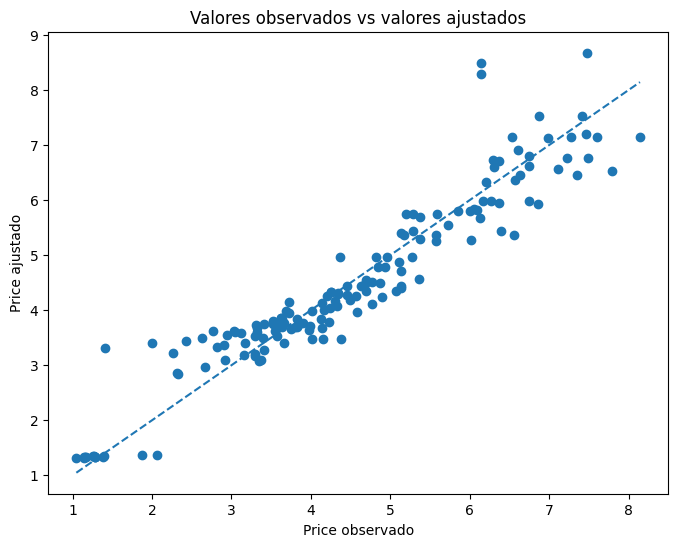

In [ ]:
import matplotlib.pyplot as plt

# Valores ajustados por el modelo
Y_ajustado = regression_noMlc_model.fittedvalues

plt.figure(figsize=(8, 6))

plt.scatter(Y, Y_ajustado)

# Línea ideal: observado = ajustado
plt.plot(
    [Y.min(), Y.max()],
    [Y.min(), Y.max()],
    linestyle="--"
)

plt.xlabel("Price observado")
plt.ylabel("Price ajustado")
plt.title("Valores observados vs valores ajustados")

plt.show()

El $R^2$ pasó de 0.966 a 0.963, mientras que el $R^2$ ajustado pasó de 0.963 a 0.961. Por lo tanto, aunque se eliminaron cuatro variables, la capacidad explicativa del modelo se mantuvo prácticamente igual, conservando aproximadamente el 96 % de la variabilidad de Price.

Uno de los principales cambios se observa en la significancia de los coeficientes. En el modelo inicial, varias variables presentaban valores de $p$ elevados, mientras que en el modelo corregido todas las variables conservadas resultaron estadísticamente significativas al 5%. Destaca especialmente Length1, cuyo error estándar disminuyó de aproximadamente 0.127 a 0.004 y cuyo estadístico $t$ aumentó de 0.800 a 28.476. Esto muestra una mejora considerable en la precisión de su estimación después de reducir la multicolinealidad.

La mejora más evidente se encuentra en el número de condición, que disminuyó de $1.67\times10^4$ a 279. De esta manera, desaparece la advertencia de problemas numéricos que estaba presente en el modelo inicial, lo que indica una mejora importante en la estabilidad de la matriz de diseño y de las estimaciones obtenidas.

En conjunto, el modelo corregido conserva prácticamente la misma capacidad explicativa que el modelo inicial, pero presenta una mejora considerable en la estabilidad numérica y en la precisión de los coeficientes estimados. Por lo tanto, el tratamiento de la multicolinealidad cumplió con su objetivo principal.

---
**Preguntas de Análisis**

Conteste las siguientes preguntas utilizando los resultados obtenidos durante el ejercicio.
Justifique sus respuestas.

1. **¿Cuál fue el número de condición obtenido en el primer ajuste? ¿Qué información proporciona este valor acerca de la matriz de predictores?**

En el primer ajuste se obtuvo un número de condición de $1.67\times10^4$

El número de condición mide, en términos generales, qué tan cerca se encuentra la matriz de diseño de ser singular o mal condicionada. Un valor elevado indica que existen combinaciones de variables predictoras que contienen información muy similar o que algunas columnas de la matriz presentan relaciones lineales fuertes. Se basa en que una matriz singular (y por lo tanto no invertible) tiene un eigenvalor igual a 0, así si la matriz es casi singular, el eigenvalor debe ser cercano a 0 y por lo tanto el cociente de eigenvectores es grande.

Por lo tanto, el valor obtenido en el primer modelo era consistente con la presencia de multicolinealidad que posteriormente también se detectó mediante los VIF.

2. **Después de aplicar el procedimiento de eliminación basado en el VIF, ¿cómo cambió el número de condición? ¿Puede considerarse que el problema de multicolinealidad se redujo?**

Después del procedimiento de eliminación, el número de condición disminuyó de $1.67\times10^4$ a $279$

Por lo tanto, sí puede considerarse que el problema de multicolinealidad se redujo considerablemente. Además, el modelo corregido ya no presentó la advertencia asociada al número de condición que aparecía en el primer ajuste.

Sin embargo, es importante señalar que un número de condición de 279 todavía indica que existe cierto condicionamiento de la matriz, por lo que la reducción del problema no significa necesariamente que toda relación entre los predictores haya desaparecido.

3. **¿Qué variables presentaron los valores de VIF más elevados en el modelo inicial? Explique por qué estas variables podrían estar relacionadas entre sí.**

Los valores más elevados correspondieron principalmente a las variables relacionadas con las mediciones de longitud y a las variables indicadoras de Species.

En particular, se observaron aproximadamente:

* Species: Valores enormes
* Length2: 4354.94.
* Length1: 2428.54.
* Length3: 2057.88.
* Height: 37.12.
* Weight: 15.65.

Los valores extremadamente elevados de las variables Species llaman especialmente la atención. Como se discutió previamente, estos valores deben interpretarse con precaución debido a los problemas de condicionamiento y rango detectados durante el cálculo de los VIF, esto me llamo demasiado la atención decidí investigar más de ello, dicha profundización se presenta en el anexo.

En el caso de Length1, Length2 y Length3, es razonable que exista una relación fuerte porque las tres variables representan diferentes medidas de longitud del mismo pez. Por tanto, contienen información muy relacionada entre sí. Esto explica que al eliminar Length2 y posteriormente Length3, los VIF de las demás variables disminuyeran considerablemente.

También existe relación entre las dimensiones físicas del pez (Length1, Height, Weight, etc.), por lo que es esperable que algunas de estas variables compartan información.

4. **En el primer modelo no se agregó explícitamente una constante. ¿Por qué la presencia de todas las variables indicadoras de Species puede generar un problema si además se incorpora un intercepto?**

Las variables indicadoras de Species representan las siete categorías:

$$ \text{Bream, Parkki, Perch, Pike, Roach, Smelt, Whitefish}. $$

Para cada observación, exactamente una de estas variables toma el valor 1 y las demás toman el valor 0. Por ello:

$$ Species_{Bream}+\cdots+Species_{Whitefish}=1. $$

Si además se agrega una columna de intercepto, dicha columna está formada por unos, por lo que se tiene una dependencia lineal exacta:

$$ \mathbf{1} = Species_{Bream}+\cdots+Species_{Whitefish}. $$

Esto provoca que las columnas de la matriz de diseño sean linealmente dependientes, por lo que la matriz no tendría rango completo y los coeficientes del modelo no podrían determinarse de manera única. Por ello, cuando se utiliza un intercepto, normalmente se conserva una categoría como referencia y se utilizan únicamente 7-1=6 variables indicadoras.

5. **Después del proceso de eliminación algunas variables indicadoras de Species desaparecen. ¿Por qué en el modelo final es posible agregar nuevamente una constante?**

El modelo final conserva:

Species_Parkki,
Species_Perch,
Species_Roach,
Species_Smelt,
Species_Whitefish junto con Length1 y Height.

Al no encontrarse simultáneamente las siete variables indicadoras, ya no se cumple la relación

$$ Species_{Bream}+\cdots+Species_{Whitefish}=1. $$

Por lo tanto, la columna de intercepto no puede expresarse como una combinación lineal de todas las variables indicadoras presentes en el modelo, y la matriz de diseño puede conservar rango completo.

Así, es posible incorporar nuevamente la constante y obtener el modelo corregido.

6. **El procedimiento utilizado elimina en cada iteración la variable que presenta el VIF más alto. ¿Por qué puede considerarse un algoritmo glotón (greedy)?**

Se considera un algoritmo greedy (glotón) porque en cada iteración toma la decisión que parece más conveniente en ese momento, sin evaluar todas las posibles combinaciones futuras de variables.

Por ejemplo, inicialmente se eliminó Species_Pike porque presentó uno de los VIF más elevados. Posteriormente se recalcularon los VIF y se eliminó Length2, después Length3, etc.

La característica fundamental es que la decisión de eliminar una variable se toma utilizando únicamente la situación actual, sin explorar previamente cuál sería el resultado de eliminar otras variables o de realizar diferentes combinaciones de eliminación.

7. **¿Eliminar siempre la variable con mayor VIF garantiza encontrar el mejor conjunto posible de predictores? Explique qué desventajas puede tener esta estrategia.**

No. Eliminar siempre la variable con mayor VIF no garantiza encontrar el mejor conjunto posible de predictores. El principal problema es que el VIF de una variable depende de las demás variables que estén incluidas en el modelo. Al eliminar una variable, los VIF restantes pueden cambiar considerablemente.

Además, esta estrategia puede presentar varias desventajas:

* Puede eliminar una variable que sea importante desde el punto de vista teórico o práctico.
* Una variable con VIF elevado no necesariamente es una variable que deba eliminarse.
* Puede producir diferentes resultados dependiendo del orden en que se realicen las eliminaciones.
* No analiza todas las posibles combinaciones de predictores.
* Puede sacrificar capacidad explicativa o interpretabilidad para conseguir VIF bajos.
* En variables categóricas, eliminar indicadores individualmente puede modificar la representación del factor y dificultar su interpretación. Este problema fue el principal objeto de estudio de Fox y Monette (1992) que generalizarón el concepto de VIF.

Por ello, un conjunto de predictores con VIF pequeños no necesariamente es el modelo estadísticamente más apropiado.

8. **Suponga que una variable tiene un VIF elevado pero es muy importante para explicar el fenómeno estudiado. ¿Consideraría adecuado eliminarla automáticamente? Justifique su respuesta.**

No sería adecuado eliminarla automáticamente únicamente por presentar un VIF elevado.

El VIF indica que existe una relación entre esa variable y los demás predictores, pero no determina por sí mismo que la variable sea irrelevante para el fenómeno estudiado.

Si la variable tiene una importancia teórica o práctica fundamental, podría ser preferible conservarla y evaluar otras alternativas. En consecuencia, el VIF debe utilizarse como una herramienta de diagnóstico, no como una regla automática de eliminación de variables.

En este ejercicio esto resulta especialmente importante: aunque el procedimiento aplicado consiguió reducir notablemente el número de condición y los VIF, la decisión de eliminar variables no debería basarse exclusivamente en superar un umbral numérico. También deben considerarse la interpretación del modelo y la naturaleza de las variables.

---
# ANEXO

Derivado de que en el proceso de eliminación de variables por VIF, la variable categórica Species y las variables Dummies creadas para su tratamiento arrojaron muy altos valores de VIF, me llamó mucho la atención. En un primer momento pensé que estos valores tan altos tenían que ver con que para el cálculo del VIF se utiliza el coeficiente de determinación $R^2$ del siguiente modelo (cada variable independiente explicada como combinación lineal de las restantes):

$$X_{ji} = β_0+β_1X_{1i}+\cdots+β_kX_{ki}+ϵ_i$$

Así, dado que en este modelo ya se incluye un intercepto y en el cálculo del VIF se ingresaron las 7 columnas de la codificación One-Hot Encoding, entonces no se llega a un rango completo, hay una dependencia lineal perfecta y el valor de $R^2$ es numéricamente muy cercano a 1, lo que provoca que el VIF explote. Por ello, las 7 categorías presentan el mismo VIF y, cuando la primera ($\text{Species_Pike}$) es eliminada, el VIF de las restantes se estabiliza.

Una primera idea fue hacer el cálculo del VIF únicamente con 6 columnas de las 7, considerando la restante como nivel de referencia y cuyo coeficiente estaría dado por el intercepto, tal como se muestra a continuación:


In [ ]:
max_R2 = 0.7
max_vif = 1/(1-max_R2)
print(f"Máximo VIF: {max_vif}")
X_nomlc, removidas, conservadas = eliminar_multicolinealidad(X_reg.iloc[:, :-1], max_vif)
#Quitamos la último columna del Data Frame el cuál es Species_Whitefish
col_conservadas = list(X_nomlc.columns)

Máximo VIF: 3.333333333333333
=== ELIMINACIÓN PASO A PASO DE MULTICOLINEALIDAD ===

--- PASO 1 ---
VIF actual:
  Length2: 4354.94 🔴
  Length1: 2428.54 🔴
  Length3: 2057.88 🔴
  Height: 37.12 🔴
  Species_Bream: 20.91 🔴
  Weight: 15.65 🔴
  Species_Pike: 12.76 🔴
  Species_Perch: 11.24 🔴
  Species_Smelt: 6.95 🟡
  Species_Roach: 4.49 ✅
  Species_Parkki: 3.61 ✅

🗑️ ELIMINANDO: Length2 (VIF = 4354.94)
Variables restantes: ['Weight', 'Length1', 'Length3', 'Height', 'Species_Bream', 'Species_Parkki', 'Species_Perch', 'Species_Pike', 'Species_Roach', 'Species_Smelt']

--- PASO 2 ---
VIF actual:
  Length3: 1246.10 🔴
  Length1: 1047.38 🔴
  Height: 37.12 🔴
  Species_Bream: 17.34 🔴
  Weight: 15.32 🔴
  Species_Pike: 12.71 🔴
  Species_Perch: 10.16 🔴
  Species_Smelt: 6.82 🟡
  Species_Roach: 4.11 ✅
  Species_Parkki: 3.51 ✅

🗑️ ELIMINANDO: Length3 (VIF = 1246.10)
Variables restantes: ['Weight', 'Length1', 'Height', 'Species_Bream', 'Species_Parkki', 'Species_Perch', 'Species_Pike', 'Species_Roach', 'Speci

Las eliminaciones de variables en el modelo principal fueron:

['Species_Pike', 'Length2', 'Length3', 'Species_Bream', 'Weight']

Mientras que, considerando la categoría de referencia a Species_Whitefish, las eliminadas fueron:

['Length2', 'Length3', 'Length1', 'Height', 'Species_Perch']

El modelo mantiene una variable de las fuertemente correlacionadas y quita una especie, veamos qué tan bueno es esto:


In [ ]:
col_finales = col_conservadas.copy()

X_final = X_nomlc[col_finales]
X_final = sm.add_constant(X_final)
Y = fish_df1[target]

regression_noMlc_model = sm.OLS(Y,X_final).fit()
print(regression_noMlc_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.900
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     227.3
Date:                Sun, 20 Sep 2026   Prob (F-statistic):           2.98e-73
Time:                        18:54:23   Log-Likelihood:                -125.30
No. Observations:                 159   AIC:                             264.6
Df Residuals:                     152   BIC:                             286.1
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              3.2873      0.092     35.

Dónde, a pesar de reducir el número de condición, no es un cambio tan significativo como el del modelo principal. El cual incluso empeora en los supuestos de no autocorrelación o independencia y normalidad, lo que claramente no es buen método. Como comentario adicional del VIF, es que es súper sencillo calcularlos, ya que coinciden con ser los elementos de la diagonal principal de la inversa de la matriz de correlación de los predictores. Este resultado me voló la cabeza.

---

Intrigado por el funcionamiento del VIF en variables categóricas, me surgió la pregunta: ¿por qué si tenemos variables creadas a partir de una sola variable categórica (One-Hot Encoding) las estamos tratando como variables diferentes? Claramente hay una correlación interna en la codificación de las Especies, pero estamos midiendo el efecto de cada especie con las restantes, no de la variable Categoría general. Por ello, decidí investigar más a fondo este concepto, y resulta que Fox y Monette (1992) ya se habían hecho la misma pregunta, en particular cuando se tienen variables categóricas y transformaciones polinómicas de una variable en el mismo modelo (por ejemplo $X_1$ y $X_1^2$) como predictores en el modelo. Para ello, trabajaron en la varianza de los coeficientes y lograron encontrar una generalización del Variance Inflation Factor, la cual, en lugar de considerar la correlación en pares de columnas, consideraba los bloques de correlación de las columnas pertenecientes a la variable (dummies de una variable categórica o transformaciones de una variable numérica).

A continuación calcularemos el GVIF de las variables involucradas la paquetería a utilizar ya da una "equivalencia" del GVIF en términos del VIF, por ello los resultados obtenidos ya son comparables con los niveles de significancia propuestos.

El método de forma detallada se encuentra en el PDF que se subió al Classroom.

Dado que Python no tiene por defecto este cálculo, pero R si, lo que haremos será calcular iteración por iteración en código R, recordando que el límite propuesto era de $0.333$

In [ ]:
!apt-get update -qq
!apt-get install -y \
    build-essential \
    gfortran \
    libblas-dev \
    liblapack-dev \
    libcurl4-openssl-dev \
    libssl-dev \
    libxml2-dev \
    libicu-dev \
    libfontconfig1-dev \
    libfreetype6-dev \
    libharfbuzz-dev \
    libfribidi-dev

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Note, selecting 'libfreetype-dev' instead of 'libfreetype6-dev'
build-essential is already the newest version (12.10ubuntu1).
gfortran is already the newest version (4:13.2.0-7ubuntu1).
libblas-dev is already the newest version (3.12.0-3build1.1).
liblapack-dev is already the newest version (3.12.0-3build1.1).
libcurl4-openssl-dev is already the newest version (8.5.0-2ubuntu10.13).
libssl-dev is already the newest version (3.0.13-0ubuntu3.15).
libxml2-dev is already the newest version (2.9.14+dfsg-1.3ubuntu3.8).
libicu-dev is already the newest version (74.2-1ubuntu3.1).
libfreetype-dev is already the newest version (2.13.2+dfsg-1ubuntu0.1).
The following additional packages will be installed:
  libgraphi

In [ ]:
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [ ]:
%%R
R.version.string

[1] "R version 4.6.1 (2026-06-24)"


In [ ]:
%%R
install.packages("gsl", repos="https://cloud.r-project.org")
library(gsl)
packageVersion("gsl")

[1] ‘2.1.9’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cloud.r-project.org/src/contrib/gsl_2.1-9.tar.gz'
Content type 'application/x-gzip' length 232420 bytes (226 KB)
downloaded 226 KB


The downloaded source packages are in
	‘/tmp/RtmpwFZFVv/downloaded_packages’


In [ ]:
!apt-get update -qq
!apt-get install -y r-cran-reformulas

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  r-cran-rbibutils r-cran-rdpack
Suggested packages:
  r-cran-gbrd r-cran-lme4 r-cran-tinytest r-cran-glmmtmb r-cran-formula
The following NEW packages will be installed:
  r-cran-rbibutils r-cran-rdpack r-cran-reformulas
0 upgraded, 3 newly installed, 0 to remove and 9 not upgraded.
Need to get 1,721 kB of archives.
After this operation, 4,830 kB of additional disk space will be used.
Get:1 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 r-cran-rbibutils amd64 2.4.1-1.ca2404.1 [950 kB]
Get:2 https://r2u.stat.illinois.edu/ubuntu noble/main all r-cran-rdpack all 2.6.6-1.ca2404.1 [621 kB]
Get:3 https://r2u.stat.illinois.edu/ubuntu noble/main all r-c

In [ ]:
%%R
library(reformulas)
packageVersion("reformulas")

[1] ‘0.4.4’


In [ ]:
%%R
install.packages("lme4", repos = "https://cloud.r-project.org")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cloud.r-project.org/src/contrib/lme4_2.0-6.tar.gz'
Content type 'application/x-gzip' length 4266192 bytes (4.1 MB)
downloaded 4.1 MB


The downloaded source packages are in
	‘/tmp/RtmpwFZFVv/downloaded_packages’


In [ ]:
%%R
library(lme4)
packageVersion("lme4")

[1] ‘2.0.6’


Loading required package: Matrix

Attaching package: ‘lme4’

The following objects are masked from ‘package:reformulas’:

    expandDoubleVerts, findbars, isNested, mkReTrms, nobars, reOnly,
    subbars



In [ ]:
%%R
install.packages("semEff", repos = "https://cloud.r-project.org")
library(semEff)
packageVersion("semEff")

[1] ‘0.7.2’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cloud.r-project.org/src/contrib/semEff_0.7.2.tar.gz'
Content type 'application/x-gzip' length 1173743 bytes (1.1 MB)
downloaded 1.1 MB


The downloaded source packages are in
	‘/tmp/RtmpwFZFVv/downloaded_packages’

Attaching package: ‘semEff’

The following object is masked from ‘package:lme4’:

    getData



Después de que haya sido súper dificil instalar R y las paqueterías JAJAJ procedemos:

# Iteración 1
Cálculamos los primeros GVIF (por ello los GVIF de las variables dummies son iguales, es un solor valor para toda la variable categórica), es importante señalar que el nivel de referencia es SpeciesBream, por ello no aparece.

In [ ]:
%%R -i fish_df

m <- lm(Price ~ Species + Weight + Length1 + Length2 + Length3 + Height, data = fish_df)
VIF(m)

   SpeciesParkki     SpeciesPerch      SpeciesPike     SpeciesRoach 
        3.236572         3.236572         3.236572         3.236572 
    SpeciesSmelt SpeciesWhitefish           Weight          Length1 
        3.236572         3.236572        15.645706      2428.538157 
         Length2          Length3           Height 
     4354.938677      2057.881409        37.123469 


Podemos observar que los GVIF de las variables numéricas se mantienen, el único modificado son los de las variables categóricas, las cuales claramente son menores a 3.33 y por lo tanto no eliminamos ninguna categoría. El GVIF más grande es Length2 por lo que la eliminamos y recalculamos los GVIF.

# Iteración 2

Volvemos a crear el modelo de regresión sin la variable Length2

In [ ]:
%%R -i fish_df

m <- lm(Price ~ Species + Weight + Length1 + Length3 + Height, data = fish_df)
VIF(m)

   SpeciesParkki     SpeciesPerch      SpeciesPike     SpeciesRoach 
        2.813821         2.813821         2.813821         2.813821 
    SpeciesSmelt SpeciesWhitefish           Weight          Length1 
        2.813821         2.813821        15.323434      1047.380097 
         Length3           Height 
     1246.104370        37.120990 


El GVIF de las Species decae aún más y los de las variables restantes también, sin embargo aún hay altos GVIF, el mayor ahora corresponde a Lenght3. Repetimos el proceso

# Iteración 3

Modelo sin Lenght2 y Lenght3

In [ ]:
%%R -i fish_df

m <- lm(Price ~ Species + Weight + Length1 + Height, data = fish_df)
VIF(m)

   SpeciesParkki     SpeciesPerch      SpeciesPike     SpeciesRoach 
        2.130374         2.130374         2.130374         2.130374 
    SpeciesSmelt SpeciesWhitefish           Weight          Length1 
        2.130374         2.130374        14.468390        37.209882 
          Height 
       34.552504 


Los GVIF disminuyen sobre todo los de las especies y ahora el mayor es el de Lenght1, lo eliminamos y volvemos a calcular:

# Iteración 4

In [ ]:
%%R -i fish_df

m <- lm(Price ~ Species + Weight + Height, data = fish_df)
VIF(m)

   SpeciesParkki     SpeciesPerch      SpeciesPike     SpeciesRoach 
        1.585009         1.585009         1.585009         1.585009 
    SpeciesSmelt SpeciesWhitefish           Weight           Height 
        1.585009         1.585009         8.111699        20.976887 


Ahora el mayor GVIF es el de Height, la quitamos y repetimos:

# Iteración 5

In [ ]:
%%R -i fish_df

m <- lm(Price ~ Species + Weight, data = fish_df)
VIF(m)

   SpeciesParkki     SpeciesPerch      SpeciesPike     SpeciesRoach 
         1.08038          1.08038          1.08038          1.08038 
    SpeciesSmelt SpeciesWhitefish           Weight 
         1.08038          1.08038          1.59023 


Todos los GVIF están por debajo del umbral propuesto de 3.33 por lo que nos quedamos con ellos, este modelo esta compuesto por el tipo de especie del pez y de su peso, una interpretación súper buena para el modelo, sin eliminar especies, pero veamos si el modelo es bueno. Dado que no eliminamos

In [ ]:
%%R -i fish_df
m <- lm(Price ~ Species + Weight, data = fish_df)
summary(m)


Call:
lm(formula = Price ~ Species + Weight, data = fish_df)

Residuals:
     Min       1Q   Median       3Q      Max 
-2.33077 -0.23674  0.03958  0.28369  1.28998 

Coefficients:
                   Estimate Std. Error t value Pr(>|t|)    
(Intercept)       3.0521921  0.1319362  23.134  < 2e-16 ***
SpeciesParkki    -0.4266994  0.2013136  -2.120   0.0357 *  
SpeciesPerch      0.2239007  0.1228786   1.822   0.0704 .  
SpeciesPike      -0.7290842  0.1619261  -4.503 1.33e-05 ***
SpeciesRoach      0.0210573  0.1685970   0.125   0.9008    
SpeciesSmelt     -1.7550785  0.1957632  -8.965 1.10e-15 ***
SpeciesWhitefish  0.3792735  0.2412886   1.572   0.1181    
Weight            0.0038448  0.0001528  25.161  < 2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.5453 on 151 degrees of freedom
Multiple R-squared:    0.9,	Adjusted R-squared:  0.8954 
F-statistic: 194.2 on 7 and 151 DF,  p-value: < 2.2e-16



In [ ]:
fish_df["Species"].unique()
fish_df["Species"] = fish_df["Species"].astype("category")
fish_df["Species"] = fish_df["Species"].cat.reorder_categories(
    ["Bream"] + [x for x in fish_df["Species"].cat.categories if x != "Bream"]
)

In [ ]:
import statsmodels.formula.api as smf

modelo = smf.ols(
    "Price ~ Weight + C(Species, Treatment(reference='Bream'))",
    data=fish_df
).fit()

print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.900
Model:                            OLS   Adj. R-squared:                  0.895
Method:                 Least Squares   F-statistic:                     194.2
Date:                Sun, 20 Sep 2026   Prob (F-statistic):           3.78e-72
Time:                        19:43:34   Log-Likelihood:                -125.07
No. Observations:                 159   AIC:                             266.1
Df Residuals:                     151   BIC:                             290.7
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                                            coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------

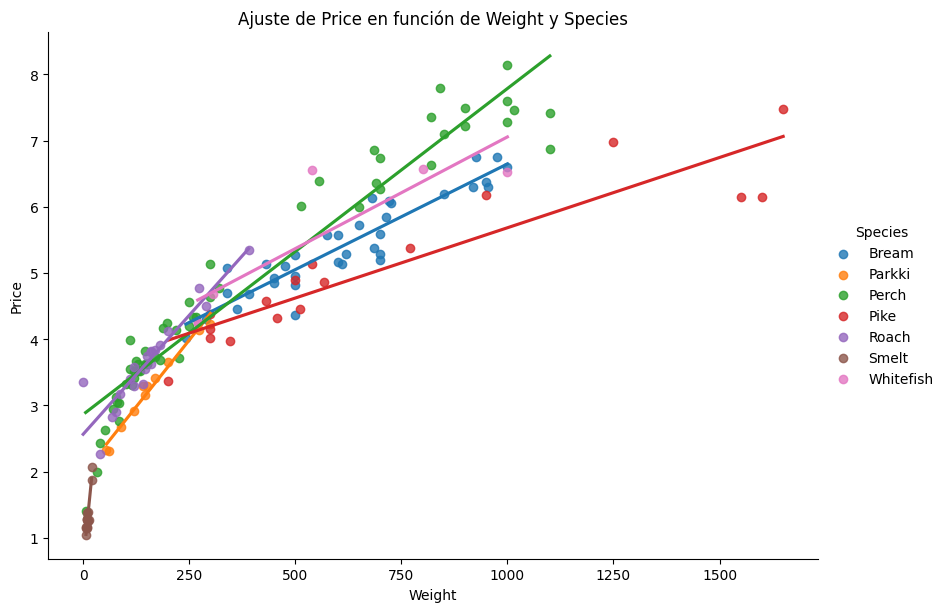

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.lmplot(
    data=fish_df,
    x="Weight",
    y="Price",
    hue="Species",
    ci=None,
    height=6,
    aspect=1.4
)

plt.title("Ajuste de Price en función de Weight y Species")
plt.xlabel("Weight")
plt.ylabel("Price")
plt.show()

Y a pesar de todo el Número de Condición es todavía muy grande, y es que según los coeficientes hay multicolinealidad en las variables dummies. Es decir para especies del mismo tipo y tipos similares hay precios similares. Dejo el anexo porque me gusto mucho investigar sobre los GVIF jeje c:

## Referencias

1. Generalized Collinearity Diagnostics
Author(s): John Fox and Georges Monette
Source: Journal of the American Statistical Association , Mar., 1992, Vol. 87, No. 417
(Mar., 1992), pp. 178-183
Published by: Taylor & Francis, Ltd. on behalf of the American Statistical Association
Stable URL: https://www.jstor.org/stable/2290467